In [2]:
from pathlib import Path
import pandas as pd

# 自动定位项目根目录
ROOT = Path.cwd().resolve()

if not (ROOT / "outputs").exists():
    ROOT = ROOT.parent

assert (ROOT / "outputs").exists(), "未找到项目根目录，请检查 Notebook 工作路径"

# 读取 07 Notebook 已经保存的逐图对比结果
csv_path = (
    ROOT / "outputs/tables/e3_e4_plantdoc_sample_changes.csv"
)

assert csv_path.exists(), f"文件不存在：{csv_path}"

paired = pd.read_csv(csv_path)

# 确保正确与否两列是布尔类型
for col in ["e3_correct", "e4_correct"]:
    paired[col] = (
        paired[col].astype(str).str.lower() == "true"
    )

print("成功加载 PlantDoc 逐图预测结果！")
print("数据量：", len(paired))
print("数据列：", paired.columns.tolist())

display(paired.head(3))

成功加载 PlantDoc 逐图预测结果！
数据量： 629
数据列： ['image_path', 'original_split', 'true_index', 'true_label', 'predicted_index_e3', 'predicted_label_e3', 'confidence_e3', 'predicted_index_e4', 'predicted_label_e4', 'confidence_e4', 'e3_correct', 'e4_correct', 'status']


,image_path,original_split,true_index,true_label,predicted_index_e3,predicted_label_e3,confidence_e3,predicted_index_e4,predicted_label_e4,confidence_e4,e3_correct,e4_correct,status
0,data/plantdoc/test/tomato_leaf_bacterial_spot/...,test,0,tomato_bacterial_spot,2,tomato_late_blight,0.976542,4,tomato_septoria_leaf_spot,0.588267,False,False,两者都错误
1,data/plantdoc/test/tomato_leaf_bacterial_spot/...,test,0,tomato_bacterial_spot,4,tomato_septoria_leaf_spot,0.965007,4,tomato_septoria_leaf_spot,0.932019,False,False,两者都错误
2,data/plantdoc/test/tomato_leaf_bacterial_spot/...,test,0,tomato_bacterial_spot,4,tomato_septoria_leaf_spot,0.982015,4,tomato_septoria_leaf_spot,0.974968,False,False,两者都错误


In [3]:

# E5-1：检查 PlantDoc 数据来源、类别分布和当前性能
import pandas as pd

print("=== 1. PlantDoc 样本来源 ===")
display(
    paired["original_split"]
    .value_counts()
    .rename_axis("来源")
    .reset_index(name="样本数")
)

print("\n=== 2. 不同来源的八类别分布 ===")
class_distribution = pd.crosstab(
    paired["true_label"],
    paired["original_split"],
    margins=True
)
display(class_distribution)

print("\n=== 3. 不同来源下 E3 / E4 的准确率 ===")
source_comparison = (
    paired.groupby("original_split")
    .agg(
        样本数=("image_path", "size"),
        E3准确率=("e3_correct", "mean"),
        E4准确率=("e4_correct", "mean")
    )
    .reset_index()
)
display(source_comparison.round(4))

print("\n=== 4. 每个类别的正确识别数量 ===")
per_class = (
    paired.groupby("true_label")
    .agg(
        样本数=("image_path", "size"),
        E3正确数=("e3_correct", "sum"),
        E4正确数=("e4_correct", "sum")
    )
    .reset_index()
)
display(per_class)

print("\n=== 5. 重复记录检查 ===")
print("重复图片路径数：", paired["image_path"].duplicated().sum())


=== 1. PlantDoc 样本来源 ===


,来源,样本数
0,train,569
1,test,60



=== 2. 不同来源的八类别分布 ===


original_split,test,train,All
true_label,,,
tomato_bacterial_spot,5,68,73
tomato_early_blight,8,68,76
tomato_healthy,8,55,63
tomato_late_blight,10,92,102
tomato_leaf_mold,4,69,73
tomato_septoria_leaf_spot,9,108,117
tomato_tomato_mosaic_virus,10,43,53
tomato_tomato_yellow_leaf_curl_virus,6,66,72
All,60,569,629



=== 3. 不同来源下 E3 / E4 的准确率 ===


,original_split,样本数,E3准确率,E4准确率
0,test,60,0.2833,0.2667
1,train,569,0.2953,0.2531



=== 4. 每个类别的正确识别数量 ===


,true_label,样本数,E3正确数,E4正确数
0,tomato_bacterial_spot,73,1,1
1,tomato_early_blight,76,46,59
2,tomato_healthy,63,3,2
3,tomato_late_blight,102,64,62
4,tomato_leaf_mold,73,0,0
5,tomato_septoria_leaf_spot,117,67,34
6,tomato_tomato_mosaic_virus,53,0,1
7,tomato_tomato_yellow_leaf_curl_virus,72,4,1



=== 5. 重复记录检查 ===
重复图片路径数： 0


===== E5 数据划分 =====
E5 训练集： 455
E5 验证集： 114
原始测试来源保留： 60
已知路径、来源组及精确图像指纹重叠检查：通过


,E5_train,E5_val,原始_test_保留
label,,,
tomato_bacterial_spot,53,15,5
tomato_early_blight,55,13,8
tomato_healthy,44,11,8
tomato_late_blight,74,18,10
tomato_leaf_mold,55,14,4
tomato_septoria_leaf_spot,83,25,9
tomato_tomato_mosaic_virus,37,6,10
tomato_tomato_yellow_leaf_curl_virus,54,12,6


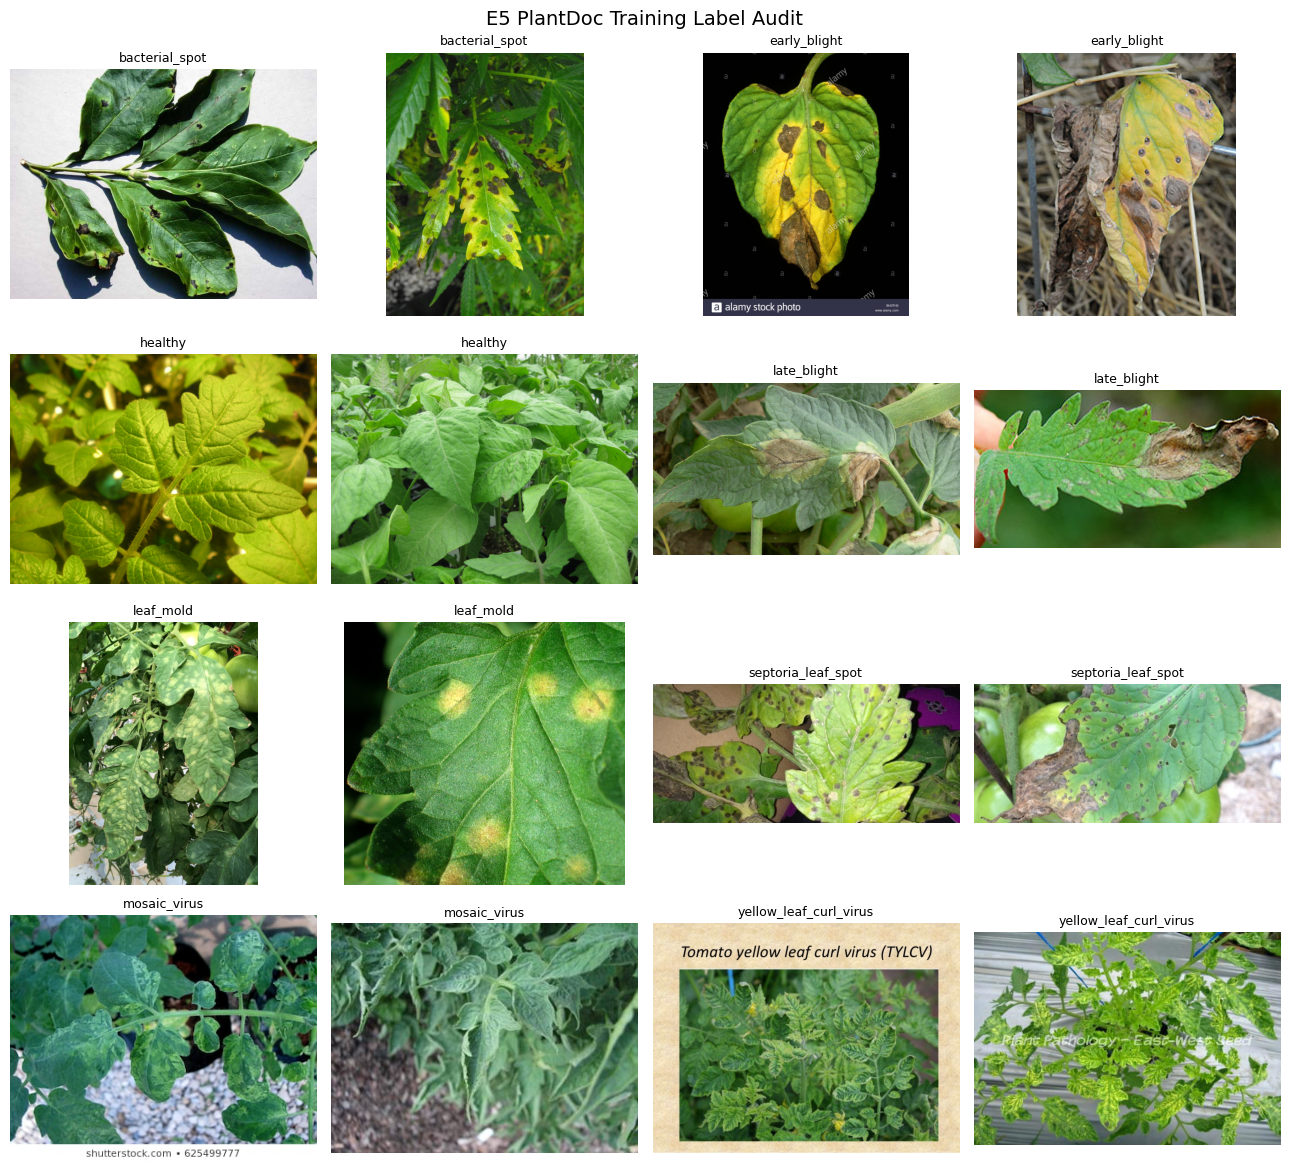

训练清单： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/data/splits/e5_pd_train.csv
验证清单： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/data/splits/e5_pd_val.csv


In [4]:
# E5-2：PlantDoc 目标域训练/验证划分
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

# 1. 定位项目根目录
ROOT = Path.cwd().resolve()
while not (ROOT / "configs/base.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("找不到 plant-disease-project 项目根目录")
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import read_manifest

# 2. 读取原始 PlantDoc 清单
source_train = pd.DataFrame(
    read_manifest(ROOT / "data/splits/plantdoc_external_train.csv")
)
source_test = pd.DataFrame(
    read_manifest(ROOT / "data/splits/plantdoc_external_test.csv")
)

assert len(source_train) == 569
assert len(source_test) == 60
assert set(source_train["original_split"]) == {"train"}
assert set(source_test["original_split"]) == {"test"}
assert source_train["label_index"].nunique() == 8

# 3. 按类别和来源组划分，固定随机种子
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 从五个候选折中选类别分布最接近 20% 的一折
candidates = []
for tr_idx, va_idx in splitter.split(
    source_train,
    y=source_train["label_index"],
    groups=source_train["group_id"]
):
    val_part = source_train.iloc[va_idx]
    counts = val_part["label_index"].value_counts()
    if len(counts) != 8:
        continue

    expected = source_train["label_index"].value_counts() * 0.2
    score = (
        (counts.reindex(expected.index, fill_value=0) - expected)
        .abs()
        .sum()
    )
    candidates.append((score, tr_idx, va_idx))

assert candidates, "没有得到覆盖八个类别的验证集"

_, tr_idx, va_idx = min(candidates, key=lambda x: x[0])

e5_train = source_train.iloc[tr_idx].copy()
e5_val = source_train.iloc[va_idx].copy()

# 4. 检查数据隔离
for key in ["image_path", "group_id", "sha256", "pixel_sha256"]:
    train_values = set(e5_train[key])
    val_values = set(e5_val[key])
    test_values = set(source_test[key])

    assert not (train_values & val_values), f"{key}: 训练/验证重叠"
    assert not (train_values & test_values), f"{key}: 训练/原始测试重叠"
    assert not (val_values & test_values), f"{key}: 验证/原始测试重叠"

assert len(e5_train) + len(e5_val) == 569
assert set(e5_train["label_index"]) == set(range(8))
assert set(e5_val["label_index"]) == set(range(8))

# 5. 保存独立清单，不覆盖任何原始文件
split_dir = ROOT / "data/splits"
train_file = split_dir / "e5_pd_train.csv"
val_file = split_dir / "e5_pd_val.csv"

e5_train.sort_values("image_path").to_csv(
    train_file, index=False, encoding="utf-8-sig"
)
e5_val.sort_values("image_path").to_csv(
    val_file, index=False, encoding="utf-8-sig"
)

# 6. 显示分区情况
summary = pd.DataFrame({
    "E5_train": e5_train.groupby("label").size(),
    "E5_val": e5_val.groupby("label").size(),
    "原始_test_保留": source_test.groupby("label").size()
}).fillna(0).astype(int)

print("===== E5 数据划分 =====")
print("E5 训练集：", len(e5_train))
print("E5 验证集：", len(e5_val))
print("原始测试来源保留：", len(source_test))
print("已知路径、来源组及精确图像指纹重叠检查：通过")

display(summary)

# 7. 从 E5 训练集抽样检查标签
examples = (
    e5_train.groupby("label", group_keys=False)
    .sample(n=2, random_state=42)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(4, 4, figsize=(13, 12))

for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    with Image.open(ROOT / row["image_path"]) as im:
        ax.imshow(im.convert("RGB"))

    ax.set_title(
        row["label"].replace("tomato_", ""),
        fontsize=9
    )
    ax.axis("off")

plt.suptitle("E5 PlantDoc Training Label Audit", fontsize=14)
plt.tight_layout()
plt.show()

print("训练清单：", train_file)
print("验证清单：", val_file)

In [5]:

# E5-A / E5-B：实验初始化与数据隔离检查

from pathlib import Path
from copy import deepcopy
from datetime import datetime
import hashlib
import json
import gc
import time
import uuid
import sys

import torch
import pandas as pd

# 自动定位项目根目录
ROOT = Path.cwd().resolve()

while not (ROOT / "configs/base.yaml").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("找不到 plant-disease-project")
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import (
    read_manifest,
    make_loader,
    build_transforms,
    dataset_fingerprint
)
from src.evaluate import (
    load_trained_model,
    classification_metrics
)
from src.experiments import selected_run
from src.utils import (
    get_device,
    set_seed,
    save_json,
    load_labels
)

# 固定实验参数
SEED = 42
MAX_EPOCHS = 8
PATIENCE = 3
BATCH_SIZE = 16
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

DEVICE = get_device("auto")

TRAIN_FILE = ROOT / "data/splits/e5_pd_train.csv"
VAL_FILE = ROOT / "data/splits/e5_pd_val.csv"
HELD_OUT_FILE = (
    ROOT / "data/splits/plantdoc_external_test.csv"
)

# 获取 E3 最佳模型
try:
    E3_RUN = selected_run(ROOT, "E3")
except ValueError:
    E3_RUN = (
        ROOT / "outputs/runs/"
        "e3_efficientnet_b0_full_combined_s42_"
        "20261021T065510_c05233"
    )

# E4 这次实际训练完成的模型
E4_RUN = (
    ROOT / "outputs/runs/"
    "e4_field_robust_v1_20261021T102435_db9cb6"
)

for path in [
    TRAIN_FILE, VAL_FILE, HELD_OUT_FILE,
    E3_RUN / "best.pt", E4_RUN / "best.pt"
]:
    assert path.is_file(), f"文件不存在：{path}"

# 检查 E5 训练/验证/原始测试的隔离
train_rows = read_manifest(TRAIN_FILE)
val_rows = read_manifest(VAL_FILE)
held_out_rows = read_manifest(HELD_OUT_FILE)

assert len(train_rows) + len(val_rows) == 569
assert len(held_out_rows) == 60

for name, rows in [
    ("train", train_rows),
    ("val", val_rows)
]:
    assert all(
        row["dataset"] == "plantdoc"
        and row["original_split"] == "train"
        for row in rows
    ), f"{name} 混入非原始 train 来源"

    assert {
        row["label_index"] for row in rows
    } == set(range(8)), f"{name} 未包含完整八类"

for key in [
    "image_path", "sha256",
    "pixel_sha256", "group_id"
]:
    a = {r[key] for r in train_rows}
    b = {r[key] for r in val_rows}
    c = {r[key] for r in held_out_rows}

    assert a.isdisjoint(b), f"{key}: train/val 重叠"
    assert a.isdisjoint(c), f"{key}: train/test 重叠"
    assert b.isdisjoint(c), f"{key}: val/test 重叠"

# 保存划分文件的哈希，用于复现
def file_sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

SPLIT_HASHES = {
    "e5_train": file_sha256(TRAIN_FILE),
    "e5_val": file_sha256(VAL_FILE),
    "plantdoc_original_test": file_sha256(HELD_OUT_FILE),
}

set_seed(SEED)

print("===== E5 双模型实验准备完成 =====")
print("设备：", DEVICE)
print("E3：", E3_RUN.name)
print("E4：", E4_RUN.name)
print("E5 训练样本：", len(train_rows))
print("E5 验证样本：", len(val_rows))
print("原始 test 保留样本：", len(held_out_rows))
print("训练/验证/原始 test 隔离检查：通过")


===== E5 双模型实验准备完成 =====
设备： mps
E3： e3_efficientnet_b0_full_combined_s42_20261021T065510_c05233
E4： e4_field_robust_v1_20261021T102435_db9cb6
E5 训练样本： 455
E5 验证样本： 114
原始 test 保留样本： 60
训练/验证/原始 test 隔离检查：通过


In [6]:

# E5：统一的分类头微调函数

def run_e5_finetuning(experiment_name, parent_run):

    # 两条实验从完全相同的随机种子开始
    set_seed(SEED)

    model, parent_checkpoint = load_trained_model(
        parent_run,
        device=DEVICE
    )

    assert parent_checkpoint["model_name"] == "efficientnet_b0"

    class_names = parent_checkpoint["class_names"]
    official_names = [
        item["label"] for item in load_labels(ROOT)
    ]
    assert class_names == official_names

    assert (
        parent_checkpoint["dataset_fingerprint"]
        == dataset_fingerprint(ROOT)
    ), "原始数据版本与基础模型不一致"

    # 冻结全部参数，再开放分类头
    for parameter in model.parameters():
        parameter.requires_grad = False

    for parameter in model.classifier.parameters():
        parameter.requires_grad = True

    # 训练与验证使用固定预处理
    data_cfg = parent_checkpoint["config"]["data"]

    transform_args = {
        key: data_cfg[key]
        for key in ("image_size", "mean", "std")
        if key in data_cfg
    }

    train_loader = make_loader(
        TRAIN_FILE,
        ROOT,
        build_transforms("basic", **transform_args),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        seed=SEED
    )

    val_loader = make_loader(
        VAL_FILE,
        ROOT,
        build_transforms("none", **transform_args),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        seed=SEED
    )

    # 定义验证：完整八类别计算 Macro-F1
    @torch.inference_mode()
    def evaluate(model):
        model.eval()

        truth = []
        predictions = []

        for images, labels in val_loader:
            images = images.to(DEVICE)

            logits = model(images)
            predicted = logits.argmax(dim=1)

            truth.extend(labels.tolist())
            predictions.extend(
                predicted.cpu().tolist()
            )

        return classification_metrics(
            truth, predictions, class_names
        )

    # 微调前的零样本基线
    baseline = evaluate(model)

    # 新建独立实验目录
    run_id = (
        f"{experiment_name}_s{SEED}_"
        f"{datetime.now():%Y%m%dT%H%M%S}_"
        f"{uuid.uuid4().hex[:6]}"
    )

    run_dir = ROOT / "outputs/runs" / run_id
    run_dir.mkdir(parents=True, exist_ok=False)

    # 配置保留父模型设置，同时记录目标域适应信息
    config = deepcopy(parent_checkpoint["config"])

    config["experiment_stage"] = "E5"
    config["experiment_name"] = experiment_name
    config["parent_run_id"] = parent_run.name
    config["seed"] = SEED

    config["model"]["finetuning"] = "freeze"

    config["data"]["train_manifest"] = (
        "data/splits/e5_pd_train.csv"
    )
    config["data"]["val_manifest"] = (
        "data/splits/e5_pd_val.csv"
    )

    config["augmentation"] = "basic"

    config["training"].update({
        "epochs": MAX_EPOCHS,
        "batch_size": BATCH_SIZE,
        "lr": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "patience": PATIENCE,
        "num_workers": 0,
        "monitor": "val_macro_f1",
        "early_stopping": True
    })

    config["e5_adaptation"] = {
        "training_domain": "plantdoc",
        "source_model": parent_run.name,
        "trainable_layers": "classifier_only",
        "split_sha256": SPLIT_HASHES,
        "validation_rule": "max_macro_f1",
        "original_test_used_for_selection": False
    }

    # JSON 是合法的 YAML 格式，可由 load_config 正常读取
    save_json(run_dir / "config.yaml", config)
    save_json(run_dir / "baseline_metrics.json", baseline)
    save_json(run_dir / "label_mapping.json", {
        "class_names": class_names
    })

    status = {
        "run_id": run_id,
        "status": "running",
        "parent_run_id": parent_run.name,
        "epochs_completed": 0,
        "best_epoch": None,
        "best_score": None
    }

    save_json(run_dir / "status.json", status)

    optimizer = torch.optim.AdamW(
        model.classifier.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    criterion = torch.nn.CrossEntropyLoss()

    best_f1 = -1.0
    best_epoch = 0
    best_metrics = None
    stale_epochs = 0
    history = []

    started = time.perf_counter()

    print(f"\n===== {experiment_name} 开始训练 =====")
    print("初始模型：", parent_run.name)
    print("运行目录：", run_id)
    print(
        f"初始验证 Accuracy={baseline['accuracy']:.4f}, "
        f"Macro-F1={baseline['macro_f1']:.4f}"
    )

    try:
        for epoch in range(1, MAX_EPOCHS + 1):

            # 冻结骨干的 BatchNorm 统计量
            model.eval()

            # 分类头包含 Dropout，训练时启用
            model.classifier.train()

            loss_sum = 0.0
            sample_count = 0

            for images, labels in train_loader:
                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                optimizer.zero_grad(set_to_none=True)

                logits = model(images)
                loss = criterion(logits, labels)

                if not torch.isfinite(loss).item():
                    raise RuntimeError(
                        "训练损失出现 NaN 或 Inf"
                    )

                loss.backward()
                optimizer.step()

                loss_sum += (
                    loss.item() * labels.size(0)
                )
                sample_count += labels.size(0)

            train_loss = loss_sum / sample_count
            val_metrics = evaluate(model)

            val_f1 = val_metrics["macro_f1"]

            history.append({
                "epoch": epoch,
                "train_loss": train_loss,
                "val_accuracy": val_metrics["accuracy"],
                "val_macro_f1": val_f1,
                "elapsed_seconds": (
                    time.perf_counter() - started
                )
            })

            print(
                f"{experiment_name} | Epoch {epoch}: "
                f"loss={train_loss:.4f}, "
                f"val_acc={val_metrics['accuracy']:.4f}, "
                f"val_macro_f1={val_f1:.4f}"
            )

            # 仅根据 E5 验证集选择最佳模型
            if val_f1 > best_f1:

                best_f1 = val_f1
                best_epoch = epoch
                best_metrics = val_metrics
                stale_epochs = 0

                checkpoint = {
                    "model_name": parent_checkpoint["model_name"],
                    "model_state_dict": {
                        k: v.detach().cpu().clone()
                        for k, v in model.state_dict().items()
                    },
                    "class_names": class_names,
                    "class_to_idx": {
                        name: i
                        for i, name in enumerate(class_names)
                    },
                    "config": config,
                    "epoch": epoch,
                    "monitor": "val_macro_f1",
                    "validation_metrics": val_metrics,
                    "dataset_fingerprint":
                        parent_checkpoint["dataset_fingerprint"],
                    "parent_run_id": parent_run.name,
                    "smoke_test": False
                }

                # 避免权重写入中断损坏正式文件
                temp_path = run_dir / "best.pt.tmp"
                torch.save(checkpoint, temp_path)
                temp_path.replace(run_dir / "best.pt")

                del checkpoint

            else:
                stale_epochs += 1

            # 每轮保存历史和状态
            pd.DataFrame(history).to_csv(
                run_dir / "history.csv",
                index=False,
                encoding="utf-8-sig"
            )

            status.update({
                "epochs_completed": epoch,
                "best_epoch": best_epoch,
                "best_score": best_f1,
                "validation_metrics": best_metrics
            })
            save_json(run_dir / "status.json", status)

            if stale_epochs >= PATIENCE:
                print("触发 Early Stopping")
                break

        status.update({
            "status": "completed",
            "seconds": time.perf_counter() - started
        })
        save_json(run_dir / "status.json", status)

        print(f"\n{experiment_name} 训练完成")
        print("最佳轮次：", best_epoch)
        print("最佳 Macro-F1：", round(best_f1, 4))

        result = {
            "experiment": experiment_name,
            "run_id": run_id,
            "parent": parent_run.name,
            "baseline_accuracy": baseline["accuracy"],
            "baseline_macro_f1": baseline["macro_f1"],
            "best_val_accuracy": best_metrics["accuracy"],
            "best_val_macro_f1": best_f1,
            "best_epoch": best_epoch,
            "epochs_completed": len(history),
            "seconds": status["seconds"],
            "run_dir": str(run_dir)
        }

        return result

    except BaseException as error:
        status.update({
            "status": "interrupted"
                if isinstance(error, KeyboardInterrupt)
                else "failed",
            "error": str(error),
            "error_type": type(error).__name__,
            "seconds": time.perf_counter() - started
        })
        save_json(run_dir / "status.json", status)
        raise

    finally:
        del model, optimizer
        gc.collect()

        if DEVICE.type == "mps":
            torch.mps.empty_cache()


In [7]:

# E5 正式对照实验：E3 与 E4 分别进行目标域微调

E5_RESULTS = []

experiments = [
    ("e5_a_e3_plantdoc_head", E3_RUN),
    ("e5_b_e4_plantdoc_head", E4_RUN)
]

for name, parent in experiments:

    result = run_e5_finetuning(
        experiment_name=name,
        parent_run=parent
    )

    E5_RESULTS.append(result)

# 展示最终对比表
e5_comparison = pd.DataFrame(E5_RESULTS)

columns = [
    "experiment",
    "baseline_accuracy",
    "baseline_macro_f1",
    "best_val_accuracy",
    "best_val_macro_f1",
    "best_epoch",
    "epochs_completed",
    "seconds"
]

print("\n===== E5-A / E5-B 对照结果 =====")
display(e5_comparison[columns].round(4))

# 分别计算相对自身初始模型的变化
e5_comparison["f1_change"] = (
    e5_comparison["best_val_macro_f1"]
    - e5_comparison["baseline_macro_f1"]
)

print("\n===== 微调前后 Macro-F1 变化 =====")

display(
    e5_comparison[
        [
            "experiment",
            "baseline_macro_f1",
            "best_val_macro_f1",
            "f1_change"
        ]
    ].round(4)
)

# 保存总表
output_file = (
    ROOT / "outputs/tables/"
    "e5_domain_adaptation_comparison.csv"
)

output_file.parent.mkdir(
    parents=True, exist_ok=True
)

e5_comparison.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("\n对比表已保存：", output_file)

for item in E5_RESULTS:
    print(
        item["experiment"],
        "最佳模型：",
        Path(item["run_dir"]) / "best.pt"
    )



===== e5_a_e3_plantdoc_head 开始训练 =====
初始模型： e3_efficientnet_b0_full_combined_s42_20261021T065510_c05233
运行目录： e5_a_e3_plantdoc_head_s42_20261021T193406_c9fd49
初始验证 Accuracy=0.2895, Macro-F1=0.1643
e5_a_e3_plantdoc_head | Epoch 1: loss=4.6210, val_acc=0.3070, val_macro_f1=0.1999
e5_a_e3_plantdoc_head | Epoch 2: loss=4.1190, val_acc=0.3421, val_macro_f1=0.2534
e5_a_e3_plantdoc_head | Epoch 3: loss=3.6587, val_acc=0.3421, val_macro_f1=0.2598
e5_a_e3_plantdoc_head | Epoch 4: loss=3.2736, val_acc=0.3596, val_macro_f1=0.2842
e5_a_e3_plantdoc_head | Epoch 5: loss=2.8982, val_acc=0.3509, val_macro_f1=0.2895
e5_a_e3_plantdoc_head | Epoch 6: loss=2.6327, val_acc=0.3246, val_macro_f1=0.2705
e5_a_e3_plantdoc_head | Epoch 7: loss=2.4469, val_acc=0.3246, val_macro_f1=0.2774
e5_a_e3_plantdoc_head | Epoch 8: loss=2.2918, val_acc=0.3684, val_macro_f1=0.3191

e5_a_e3_plantdoc_head 训练完成
最佳轮次： 8
最佳 Macro-F1： 0.3191

===== e5_b_e4_plantdoc_head 开始训练 =====
初始模型： e4_field_robust_v1_20261021T102435_db9cb6
运

,experiment,baseline_accuracy,baseline_macro_f1,best_val_accuracy,best_val_macro_f1,best_epoch,epochs_completed,seconds
0,e5_a_e3_plantdoc_head,0.2895,0.1643,0.3684,0.3191,8,8,47.5828
1,e5_b_e4_plantdoc_head,0.2368,0.1169,0.3684,0.3129,7,8,43.6289



===== 微调前后 Macro-F1 变化 =====


,experiment,baseline_macro_f1,best_val_macro_f1,f1_change
0,e5_a_e3_plantdoc_head,0.1643,0.3191,0.1548
1,e5_b_e4_plantdoc_head,0.1169,0.3129,0.1960



对比表已保存： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/tables/e5_domain_adaptation_comparison.csv
e5_a_e3_plantdoc_head 最佳模型： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/runs/e5_a_e3_plantdoc_head_s42_20261021T193406_c9fd49/best.pt
e5_b_e4_plantdoc_head 最佳模型： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/runs/e5_b_e4_plantdoc_head_s42_20261021T193455_27c773/best.pt


In [8]:

# E5-A / E5-B：目标域改善与原领域性能保持检查

import pandas as pd
from src.evaluate import evaluate_checkpoint
from src.utils import load_config

E5_A_RUN = ROOT / "outputs/runs/e5_a_e3_plantdoc_head_s42_20261021T193406_c9fd49"
E5_B_RUN = ROOT / "outputs/runs/e5_b_e4_plantdoc_head_s42_20261021T193455_27c773"

PV_VAL = ROOT / "data/splits/pv_val.csv"

assert PV_VAL.is_file()

experiments = [
    ("E5-A", E5_A_RUN, "E3", 0.9948679846),
    ("E5-B", E5_B_RUN, "E4", 0.9973564099)
]

results = []
per_class = {}

for name, run_dir, parent_name, parent_pv_f1 in experiments:

    print(f"\n===== 正在检查 {name} =====")

    assert (run_dir / "best.pt").is_file()

    # 已保存的最佳 PlantDoc 开发验证指标
    status = load_config(run_dir / "status.json")
    assert status["status"] == "completed"

    pd_val = status["validation_metrics"]

    # 检查微调后 PlantVillage 验证性能
    pv_val = evaluate_checkpoint(
        ROOT,
        run_dir,
        PV_VAL,
        dataset_name="pv_val_after_e5"
    )

    results.append({
        "模型": name,
        "初始化": parent_name,
        "PlantDoc_Val_Accuracy": pd_val["accuracy"],
        "PlantDoc_Val_MacroF1": pd_val["macro_f1"],
        "原模型_PV_Val_F1": parent_pv_f1,
        "微调后_PV_Val_F1": pv_val["macro_f1"],
        "PV_F1变化": pv_val["macro_f1"] - parent_pv_f1
    })

    per_class[name] = pd_val["classification_report"]

    print(
        f"PlantDoc Val F1: {pd_val['macro_f1']:.4f}"
    )
    print(
        f"PlantVillage Val F1: {pv_val['macro_f1']:.4f}"
    )

# 整体性能对比
summary = pd.DataFrame(results)

print("\n===== E5 跨域性能权衡 =====")
display(summary.round(4))

# 八个类别的开发验证集 Recall / F1
class_names = list(per_class["E5-A"].keys())
class_names = [
    c for c in class_names
    if c.startswith("tomato_")
]

class_rows = []
for label in class_names:
    class_rows.append({
        "类别": label,
        "样本数": int(per_class["E5-A"][label]["support"]),
        "E5A_Recall": per_class["E5-A"][label]["recall"],
        "E5B_Recall": per_class["E5-B"][label]["recall"],
        "E5A_F1": per_class["E5-A"][label]["f1-score"],
        "E5B_F1": per_class["E5-B"][label]["f1-score"]
    })

class_table = pd.DataFrame(class_rows)

print("\n===== PlantDoc Val 八类别表现 =====")
display(class_table.round(4))

# 保存结果
out_dir = ROOT / "outputs/tables"
out_dir.mkdir(parents=True, exist_ok=True)

summary.to_csv(
    out_dir / "e5_domain_tradeoff.csv",
    index=False,
    encoding="utf-8-sig"
)

class_table.to_csv(
    out_dir / "e5_per_class_val.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nE5 验证检查完成！")



===== 正在检查 E5-A =====
PlantDoc Val F1: 0.3191
PlantVillage Val F1: 0.9765

===== 正在检查 E5-B =====
PlantDoc Val F1: 0.3129
PlantVillage Val F1: 0.9836

===== E5 跨域性能权衡 =====


,模型,初始化,PlantDoc_Val_Accuracy,PlantDoc_Val_MacroF1,原模型_PV_Val_F1,微调后_PV_Val_F1,PV_F1变化
0,E5-A,E3,0.3684,0.3191,0.9949,0.9765,-0.0183
1,E5-B,E4,0.3684,0.3129,0.9974,0.9836,-0.0137



===== PlantDoc Val 八类别表现 =====


,类别,样本数,E5A_Recall,E5B_Recall,E5A_F1,E5B_F1
0,tomato_bacterial_spot,15,0.2667,0.3333,0.2759,0.3571
1,tomato_early_blight,13,0.5385,0.6154,0.3415,0.3810
2,tomato_late_blight,18,0.6111,0.8333,0.5116,0.5556
3,tomato_leaf_mold,14,0.5000,0.0000,0.4118,0.0000
4,tomato_septoria_leaf_spot,25,0.2400,0.2000,0.3077,0.2326
5,tomato_tomato_mosaic_virus,6,0.0000,0.0000,0.0000,0.0000
6,tomato_tomato_yellow_leaf_curl_virus,12,0.0833,0.3333,0.1333,0.4211
7,tomato_healthy,11,0.5455,0.4545,0.5714,0.5556



E5 验证检查完成！


In [9]:

# E6-1：混合训练实验准备
from pathlib import Path
from copy import deepcopy
from datetime import datetime
from collections import Counter
import hashlib
import gc
import sys
import time
import uuid

import torch
import pandas as pd
import torch.nn.functional as F

ROOT = Path.cwd().resolve()
while not (ROOT / "configs/base.yaml").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("找不到项目根目录")
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import (
    read_manifest, make_loader, build_transforms,
    dataset_fingerprint
)
from src.evaluate import load_trained_model, classification_metrics
from src.utils import get_device, set_seed, save_json, load_labels

DEVICE = get_device("auto")
SEED = 42

E5_A_RUN = ROOT / "outputs/runs/e5_a_e3_plantdoc_head_s42_20261021T193406_c9fd49"
E5_B_RUN = ROOT / "outputs/runs/e5_b_e4_plantdoc_head_s42_20261021T193455_27c773"

PD_TRAIN = ROOT / "data/splits/e5_pd_train.csv"
PD_VAL = ROOT / "data/splits/e5_pd_val.csv"
PV_TRAIN = ROOT / "data/splits/pv_train.csv"
PV_VAL = ROOT / "data/splits/pv_val.csv"

for path in [
    E5_A_RUN / "best.pt", E5_B_RUN / "best.pt",
    PD_TRAIN, PD_VAL, PV_TRAIN, PV_VAL
]:
    assert path.is_file(), f"文件不存在：{path}"

pd_train_rows = read_manifest(PD_TRAIN)
pd_val_rows = read_manifest(PD_VAL)
pv_train_rows = read_manifest(PV_TRAIN)
pv_val_rows = read_manifest(PV_VAL)

assert len(pd_train_rows) + len(pd_val_rows) == 569
assert len(pv_train_rows) == 10543
assert len(pv_val_rows) == 2264

assert all(r["dataset"] == "plantdoc" for r in pd_train_rows + pd_val_rows)
assert all(r["original_split"] == "train" for r in pd_train_rows + pd_val_rows)
assert all(r["dataset"] == "plantvillage" for r in pv_train_rows + pv_val_rows)

# 校验四份清单已知的重复与分组问题
manifests = {
    "PD_train": pd_train_rows,
    "PD_val": pd_val_rows,
    "PV_train": pv_train_rows,
    "PV_val": pv_val_rows
}

for key in ("image_path", "sha256", "pixel_sha256", "group_id"):
    names = list(manifests)
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a = {r[key] for r in manifests[names[i]]}
            b = {r[key] for r in manifests[names[j]]}
            assert a.isdisjoint(b), (
                f"{key}: {names[i]} 与 {names[j]} 重叠"
            )

# 数据集版本记录
SPLIT_SHA256 = {
    p.name: hashlib.sha256(p.read_bytes()).hexdigest()
    for p in (PD_TRAIN, PD_VAL, PV_TRAIN, PV_VAL)
}

# E6 固定训练参数
E6_EPOCHS = 10
E6_PATIENCE = 4
E6_BATCH = 16

BACKBONE_LR = 1e-5
HEAD_LR = 1e-4

# 目标域损失占 70%，原领域占 30%
PD_LOSS_WEIGHT = 0.70
PV_LOSS_WEIGHT = 0.30

# 原领域性能约束
PV_F1_FLOOR = 0.97

print("===== E6 准备完成 =====")
print("设备：", DEVICE)
print("PlantDoc 训练：", len(pd_train_rows))
print("PlantDoc 验证：", len(pd_val_rows))
print("PlantVillage 训练：", len(pv_train_rows))
print("PlantVillage 验证：", len(pv_val_rows))
print("E6-A：", E5_A_RUN.name)
print("E6-B：", E5_B_RUN.name)
print("已知数据重叠检查：通过")
print("原始测试集：本阶段不使用")


===== E6 准备完成 =====
设备： mps
PlantDoc 训练： 455
PlantDoc 验证： 114
PlantVillage 训练： 10543
PlantVillage 验证： 2264
E6-A： e5_a_e3_plantdoc_head_s42_20261021T193406_c9fd49
E6-B： e5_b_e4_plantdoc_head_s42_20261021T193455_27c773
已知数据重叠检查：通过
原始测试集：本阶段不使用


In [10]:

# E6-2：部分骨干解冻 + 双领域混合训练

@torch.inference_mode()
def evaluate_domain(model, loader, class_names):
    model.eval()
    truth, preds = [], []

    for images, labels in loader:
        images = images.to(DEVICE)
        logits = model(images)
        truth.extend(labels.tolist())
        preds.extend(logits.argmax(1).cpu().tolist())

    return classification_metrics(truth, preds, class_names)


def run_e6(name, parent_run):
    set_seed(SEED)

    model, parent_ckpt = load_trained_model(
        parent_run, device=DEVICE
    )

    assert parent_ckpt["model_name"] == "efficientnet_b0"
    assert parent_ckpt["dataset_fingerprint"] == dataset_fingerprint(ROOT)

    class_names = parent_ckpt["class_names"]
    assert class_names == [r["label"] for r in load_labels(ROOT)]

    # 冻结骨干前部，仅解冻 EfficientNet-B0 后部和分类头
    for p in model.parameters():
        p.requires_grad = False

    for p in model.features[7:].parameters():
        p.requires_grad = True

    for p in model.classifier.parameters():
        p.requires_grad = True

    data_cfg = parent_ckpt["config"]["data"]
    tf_args = {
        k: data_cfg[k]
        for k in ("image_size", "mean", "std")
        if k in data_cfg
    }

    def loader(path, augmentation, shuffle):
        return make_loader(
            path, ROOT,
            build_transforms(augmentation, **tf_args),
            batch_size=E6_BATCH,
            shuffle=shuffle,
            num_workers=0,
            seed=SEED
        )

    # 两个训练领域分别进行增强
    pd_loader = loader(PD_TRAIN, "basic", True)
    pv_loader = loader(PV_TRAIN, "combined", True)

    # 两套验证集都不进行随机增强
    pd_val_loader = loader(PD_VAL, "none", False)
    pv_val_loader = loader(PV_VAL, "none", False)

    # PlantDoc 类别均衡：按训练集数量反平方根加权
    counts = Counter(r["label_index"] for r in pd_train_rows)
    weights = torch.tensor(
        [1.0 / (counts[i] ** 0.5) for i in range(8)],
        dtype=torch.float32,
        device=DEVICE
    )
    weights = weights / weights.mean()

    baseline_pd = evaluate_domain(model, pd_val_loader, class_names)
    baseline_pv = evaluate_domain(model, pv_val_loader, class_names)

    assert baseline_pv["macro_f1"] >= PV_F1_FLOOR, (
        "初始模型不满足 PlantVillage 性能下限"
    )

    config = deepcopy(parent_ckpt["config"])
    config["experiment_stage"] = "E6"
    config["parent_run_id"] = parent_run.name
    config["model"]["finetuning"] = "partial"
    config["training"].update({
        "epochs": E6_EPOCHS,
        "batch_size": E6_BATCH,
        "num_workers": 0,
        "patience": E6_PATIENCE,
        "monitor": "pd_val_macro_f1",
    })
    config["e6_mixture"] = {
        "pd_train": "data/splits/e5_pd_train.csv",
        "pv_train": "data/splits/pv_train.csv",
        "pd_val": "data/splits/e5_pd_val.csv",
        "pv_val": "data/splits/pv_val.csv",
        "pd_loss_weight": PD_LOSS_WEIGHT,
        "pv_loss_weight": PV_LOSS_WEIGHT,
        "pd_class_weighting": "inverse_sqrt_frequency",
        "backbone_layers": "features[7:]",
        "backbone_lr": BACKBONE_LR,
        "head_lr": HEAD_LR,
        "pv_f1_floor": PV_F1_FLOOR,
        "batch_per_domain": E6_BATCH,
        "selection": "maximize_pd_val_f1_subject_to_pv_f1_floor",
        "seed": SEED,
        "split_hashes": SPLIT_SHA256
    }

    run_id = (
        f"{name}_s{SEED}_"
        f"{datetime.now():%Y%m%dT%H%M%S}_"
        f"{uuid.uuid4().hex[:6]}"
    )
    run_dir = ROOT / "outputs/runs" / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    save_json(run_dir / "config.yaml", config)

    optimizer = torch.optim.AdamW([
        {"params": model.features[7:].parameters(), "lr": BACKBONE_LR},
        {"params": model.classifier.parameters(), "lr": HEAD_LR}
    ], weight_decay=1e-4)

    # 保存最佳模型，初始 E5 权重作为 epoch 0 基线
    def save_best(epoch, pd_metrics, pv_metrics):
        state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }
        ckpt = dict(parent_ckpt)
        ckpt.update({
            "model_state_dict": state,
            "config": config,
            "epoch": epoch,
            "monitor": "pd_val_macro_f1",
            "validation_metrics": pd_metrics,
            "pv_validation_metrics": pv_metrics,
            "parent_run_id": parent_run.name,
            "smoke_test": False
        })
        tmp = run_dir / "best.pt.tmp"
        torch.save(ckpt, tmp)
        tmp.replace(run_dir / "best.pt")

    best_pd_f1 = baseline_pd["macro_f1"]
    best_pv_f1 = baseline_pv["macro_f1"]
    best_epoch = 0
    stale = 0
    history = []
    started = time.perf_counter()

    save_best(0, baseline_pd, baseline_pv)

    print(f"\n===== {name} 开始训练 =====")
    print("初始模型：", parent_run.name)
    print(f"初始 PD Val F1: {best_pd_f1:.4f}")
    print(f"初始 PV Val F1: {best_pv_f1:.4f}")

    def save_status(state, epoch, error=None):
        save_json(run_dir / "status.json", {
            "run_id": run_id,
            "status": state,
            "epochs_completed": epoch,
            "best_epoch": best_epoch,
            "best_score": best_pd_f1,
            "best_pv_f1": best_pv_f1,
            "seconds": time.perf_counter() - started,
            "error": error
        })

    save_status("running", 0)

    try:
        for epoch in range(1, E6_EPOCHS + 1):
            model.train()

            # 保持所有 BatchNorm 运行统计固定，减少小数据域偏移
            for layer in model.modules():
                if isinstance(
                    layer, torch.nn.modules.batchnorm._BatchNorm
                ):
                    layer.eval()

            pv_iterator = iter(pv_loader)
            total_loss = 0.0
            total_steps = 0

            # 每个训练步骤各取一批 PlantDoc 和 PlantVillage
            for pd_images, pd_labels in pd_loader:
                try:
                    pv_images, pv_labels = next(pv_iterator)
                except StopIteration:
                    pv_iterator = iter(pv_loader)
                    pv_images, pv_labels = next(pv_iterator)

                pd_images = pd_images.to(DEVICE)
                pd_labels = pd_labels.to(DEVICE)
                pv_images = pv_images.to(DEVICE)
                pv_labels = pv_labels.to(DEVICE)

                optimizer.zero_grad(set_to_none=True)

                pd_logits = model(pd_images)
                pv_logits = model(pv_images)

                loss_pd = F.cross_entropy(
                    pd_logits, pd_labels, weight=weights
                )
                loss_pv = F.cross_entropy(
                    pv_logits, pv_labels
                )

                loss = (
                    PD_LOSS_WEIGHT * loss_pd
                    + PV_LOSS_WEIGHT * loss_pv
                )

                if not torch.isfinite(loss).item():
                    raise RuntimeError("损失出现 NaN 或 Inf")

                loss.backward()
                optimizer.step()

                total_loss += loss.item()
                total_steps += 1

            pd_metrics = evaluate_domain(
                model, pd_val_loader, class_names
            )
            pv_metrics = evaluate_domain(
                model, pv_val_loader, class_names
            )

            pd_f1 = pd_metrics["macro_f1"]
            pv_f1 = pv_metrics["macro_f1"]

            # 只接受满足原领域保留约束的目标域改进
            eligible = pv_f1 >= PV_F1_FLOOR
            improved = eligible and pd_f1 > best_pd_f1 + 1e-4

            if improved:
                best_pd_f1 = pd_f1
                best_pv_f1 = pv_f1
                best_epoch = epoch
                stale = 0
                save_best(epoch, pd_metrics, pv_metrics)
            else:
                stale += 1

            history.append({
                "epoch": epoch,
                "train_loss": total_loss / total_steps,
                "pd_val_accuracy": pd_metrics["accuracy"],
                "pd_val_macro_f1": pd_f1,
                "pv_val_accuracy": pv_metrics["accuracy"],
                "pv_val_macro_f1": pv_f1,
                "pv_constraint_pass": eligible,
                "selected_as_best": improved
            })

            pd.DataFrame(history).to_csv(
                run_dir / "history.csv", index=False
            )
            save_status("running", epoch)

            print(
                f"{name} | epoch {epoch}: "
                f"loss={total_loss / total_steps:.4f}, "
                f"PD_F1={pd_f1:.4f}, "
                f"PV_F1={pv_f1:.4f}, "
                f"eligible={eligible}, "
                f"best_epoch={best_epoch}"
            )

            if stale >= E6_PATIENCE:
                print("触发 Early Stopping")
                break

        save_status("completed", len(history))

        result = {
            "experiment": name,
            "parent": parent_run.name,
            "baseline_pd_f1": baseline_pd["macro_f1"],
            "baseline_pv_f1": baseline_pv["macro_f1"],
            "best_pd_f1": best_pd_f1,
            "best_pv_f1": best_pv_f1,
            "best_epoch": best_epoch,
            "epochs_completed": len(history),
            "run_dir": str(run_dir)
        }

        print(
            f"{name} 完成 | "
            f"最佳 PD F1={best_pd_f1:.4f} | "
            f"对应 PV F1={best_pv_f1:.4f}"
        )

        return result

    except BaseException as exc:
        save_status(
            "interrupted" if isinstance(exc, KeyboardInterrupt)
            else "failed",
            len(history),
            str(exc)
        )
        raise

    finally:
        del model, optimizer
        gc.collect()
        if DEVICE.type == "mps":
            torch.mps.empty_cache()


# 按顺序训练，避免 MPS 同时加载两个训练任务
e6_results = []

for name, parent in [
    ("e6_a_e5a_mixed_partial", E5_A_RUN),
    ("e6_b_e5b_mixed_partial", E5_B_RUN)
]:
    e6_results.append(run_e6(name, parent))

e6_comparison = pd.DataFrame(e6_results)

print("\n===== E6-A / E6-B 最终对照 =====")
display(e6_comparison.round(4))

out_file = ROOT / "outputs/tables/e6_comparison.csv"
out_file.parent.mkdir(parents=True, exist_ok=True)
e6_comparison.to_csv(out_file, index=False, encoding="utf-8-sig")

print("结果已保存：", out_file)



===== e6_a_e5a_mixed_partial 开始训练 =====
初始模型： e5_a_e3_plantdoc_head_s42_20261021T193406_c9fd49
初始 PD Val F1: 0.3191
初始 PV Val F1: 0.9765
e6_a_e5a_mixed_partial | epoch 1: loss=1.5404, PD_F1=0.3889, PV_F1=0.9720, eligible=True, best_epoch=1
e6_a_e5a_mixed_partial | epoch 2: loss=1.3773, PD_F1=0.4034, PV_F1=0.9687, eligible=False, best_epoch=1
e6_a_e5a_mixed_partial | epoch 3: loss=1.3259, PD_F1=0.3902, PV_F1=0.9667, eligible=False, best_epoch=1
e6_a_e5a_mixed_partial | epoch 4: loss=1.2428, PD_F1=0.4035, PV_F1=0.9641, eligible=False, best_epoch=1
e6_a_e5a_mixed_partial | epoch 5: loss=1.2152, PD_F1=0.4229, PV_F1=0.9649, eligible=False, best_epoch=1
触发 Early Stopping
e6_a_e5a_mixed_partial 完成 | 最佳 PD F1=0.3889 | 对应 PV F1=0.9720

===== e6_b_e5b_mixed_partial 开始训练 =====
初始模型： e5_b_e4_plantdoc_head_s42_20261021T193455_27c773
初始 PD Val F1: 0.3129
初始 PV Val F1: 0.9836
e6_b_e5b_mixed_partial | epoch 1: loss=1.5530, PD_F1=0.3117, PV_F1=0.9761, eligible=True, best_epoch=0
e6_b_e5b_mixed_partial

,experiment,parent,baseline_pd_f1,baseline_pv_f1,best_pd_f1,best_pv_f1,best_epoch,epochs_completed,run_dir
0,e6_a_e5a_mixed_partial,e5_a_e3_plantdoc_head_s42_20261021T193406_c9fd49,0.3191,0.9765,0.3889,0.9720,1,5,/Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片...
1,e6_b_e5b_mixed_partial,e5_b_e4_plantdoc_head_s42_20261021T193455_27c773,0.3129,0.9836,0.3733,0.9704,10,10,/Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片...


结果已保存： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/tables/e6_comparison.csv
